<p align="center">
<img src="https://upload.wikimedia.org/wikipedia/commons/thumb/a/ae/Keras_logo.svg/512px-Keras_logo.svg.png?raw=true" width="100px">
</p>


 # **<font color="DeepPink">Deep Learning con Keras</font>**

<p align="justify">
En este notebook, se aprenderá a utilizar la biblioteca Keras para construir modelos para problemas de clasificación. Se usará el popular conjunto de datos <a href="https://keras.io/api/datasets/">MNIST</a>, un conjunto de datos de imágenes, para variar.
<br><br>
La base de datos MNIST, que significa Modified National Institute of Standards and Technology database, es una gran base de datos de dígitos manuscritos que se usa comúnmente para entrenar diversos sistemas de procesamiento de imágenes.
<br><br>
La base de datos MNIST contiene 60000 imágenes de entrenamiento y 10000 imágenes de prueba de dígitos escritos por estudiantes de secundaria y empleados de la Oficina del Censo de los Estados Unidos.



 ## **<font color="DeepPink">Problema de Clasificación con Keras</font>**

In [ ]:
import numpy as np
import keras

from keras.models import Sequential
from keras.layers import Dense
from keras.utils import to_categorical

import matplotlib.pyplot as plt

<p align="justify">
Se carga el conjunto de datos MNIST, que es muy utilizado para tareas de clasificación de imágenes en el Deep Learning. Este conjunto de datos contiene imágenes de dígitos escritos a mano (del 0 al 9).
<br><br>
<code>X_train</code> e <code>y_train</code> contienen las imágenes de entrenamiento y sus etiquetas correspondientes.
<code>X_test</code> e <code>y_test</code> contienen las imágenes de prueba y sus etiquetas correspondientes.


In [ ]:
from keras.datasets import mnist
(X_train, y_train), (X_test, y_test) = mnist.load_data()

 Se confirma la cantidad de imágenes en cada conjunto. Según la documentación de los datos, deberían haber 60000 imágenes en `X_train` y 10000 imágenes en `X_test`.

In [ ]:
X_train.shape

(60000, 28, 28)

In [ ]:
X_test.shape

(10000, 28, 28)

<p align="justify">
El primer número de la tupla de salida es el número de imágenes y los otros dos números son el tamaño de las imágenes en el conjunto de datos. Entonces, cada imagen tiene 28 píxeles por 28 píxeles (784 píxeles en total).

In [ ]:
X_train[0]

array([[  0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
          0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
          0,   0],
       [  0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
          0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
          0,   0],
       [  0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
          0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
          0,   0],
       [  0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
          0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
          0,   0],
       [  0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
          0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
          0,   0],
       [  0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   3,
         18,  18,  18, 126, 136, 175,  26, 166, 255, 247, 127,   0,   0,
          0,   0],
       [  0,   0,   0,   0,   0,   0,   0,   0,  30,  36,  94, 154, 170,
        253, 253, 253, 253, 253, 225, 172, 253, 242, 195,  64,   0,   0,
          0,   0],
       [  0,   0,   0,   0,   0,   0,   0,  49, 238, 253, 253, 253, 253,
        253, 253, 253, 253, 251,  93,  82,  82,  56,  39,   0,   0,   0,
          0,   0],
       [  0,   0,   0,   0,   0,   0,   0,  18, 219, 253, 253, 253, 253,
        253, 198, 182, 247, 241,   0,   0,   0,   0,   0,   0,   0,   0,
          0,   0],
       [  0,   0,   0,   0,   0,   0,   0,   0,  80, 156, 107, 253, 253,
        205,  11,   0,  43, 154,   0,   0,   0,   0,   0,   0,   0,   0,
          0,   0],
       [  0,   0,   0,   0,   0,   0,   0,   0,   0,  14,   1, 154, 253,
         90,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
          0,   0],
       [  0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0, 139, 253,
        190,   2,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
          0,   0],
       [  0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,  11, 190,
        253,  70,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
          0,   0],
       [  0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,  35,
        241, 225, 160, 108,   1,   0,   0,   0,   0,   0,   0,   0,   0,
          0,   0],
       [  0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
         81, 240, 253, 253, 119,  25,   0,   0,   0,   0,   0,   0,   0,
          0,   0],
       [  0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
          0,  45, 186, 253, 253, 150,  27,   0,   0,   0,   0,   0,   0,
          0,   0],
       [  0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
          0,   0,  16,  93, 252, 253, 187,   0,   0,   0,   0,   0,   0,
          0,   0],
       [  0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
          0,   0,   0,   0, 249, 253, 249,  64,   0,   0,   0,   0,   0,
          0,   0],
       [  0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
          0,  46, 130, 183, 253, 253, 207,   2,   0,   0,   0,   0,   0,
          0,   0],
       [  0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,  39,
        148, 229, 253, 253, 253, 250, 182,   0,   0,   0,   0,   0,   0,
          0,   0],
       [  0,   0,   0,   0,   0,   0,   0,   0,   0,   0,  24, 114, 221,
        253, 253, 253, 253, 201,  78,   0,   0,   0,   0,   0,   0,   0,
          0,   0],
       [  0,   0,   0,   0,   0,   0,   0,   0,  23,  66, 213, 253, 253,
        253, 253, 198,  81,   2,   0,   0,   0,   0,   0,   0,   0,   0,
          0,   0],
       [  0,   0,   0,   0,   0,   0,  18, 171, 219, 253, 253, 253, 253,
        195,  80,   9,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
          0,   0],
       [  0,   0,   0,   0,  55, 172, 226, 253, 253, 253, 253, 244, 133,
         11,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
          0,   0],
       [  0,   0,   0,   0, 136, 253, 25

In [ ]:
y_train[0]

np.uint8(5)

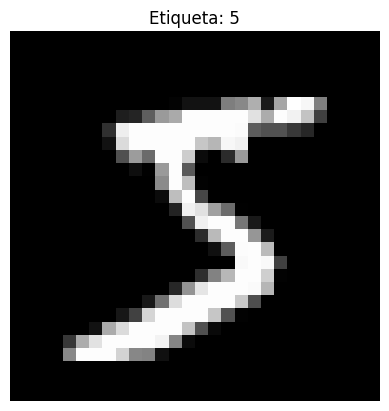

In [ ]:
# Mostrar la primera imagen del conjunto de entrenamiento
plt.imshow(X_train[0], cmap='gray')
plt.title(f'Etiqueta: {y_train[0]}')
plt.axis('off')
plt.show()

 ### **<font color="DeepPink">1. Preparar los datos</font>**

<p align="justify">
Con las redes neuronales convencionales, no es posible introducir la imagen tal como está. Entonces necesitamos aplanar (<i>flatten</i>) las imágenes en vectores unidimensionales, cada uno de tamaño 1 x (28 x 28) = 1 x 784.

In [ ]:
# aplanar imágenes en un vector unidimensional

num_pixels = X_train.shape[1] * X_train.shape[2]                                # dimensión del vector unidimensional

X_train = X_train.reshape(X_train.shape[0], num_pixels).astype('float32')       # aplana las imágenes de entrenamiento
X_test = X_test.reshape(X_test.shape[0], num_pixels).astype('float32')          # aplana las imágenes de testeo

print(num_pixels)
print(X_train.shape)
print(X_test.shape)

784
(60000, 784)
(10000, 784)


<p align="justify">
Dado que los valores de píxeles pueden oscilar entre 0 (negro) y 255 (blanco), se normalizan los vectores para que estén entre 0 y 1.

In [ ]:
# normalizar las entradas de 0-255 a 0-1
X_train = X_train / 255
X_test = X_test / 255

<p align="justify">
Finalmente, antes de comenzar a construir el modelo en Keras, para la clasificación es necesario dividir la variable objetivo en categorías. Se usa la función <code>to_categorical</code> del paquete Keras Utilities.

In [ ]:
# codificación one hot de la variable objetivo (etiquetas)
y_train = to_categorical(y_train)
y_test = to_categorical(y_test)

num_classes = y_test.shape[1]

print(num_classes)

10


 ### **<font color="DeepPink">2. Crear el modelo</font>**

<p align="justify">
El siguiente ejemplo es ampliamente utilizado en la literature de Deep Learning, en el que se pretende clasificar las imágenes en dígitos del 0 al 9.
<ul p align="justify">
<li>Cada imagen tiene 28x28 = 784 pixels, que constituyen por ende las unidades de la input layer.
<li>La primera hidden layer 1 tiene 256 neuronas. Por lo tanto, tendrá 256*784 = 200.704 weights a estimar, que sumados a los 256 términos de bias, suman un total de 200.960 parámetros a estimar.
<li>Luego, la hidden layer 2 tiene 128 neuronas. Lo cual implica 128*256+128 = 32.896 parámetros adicionales a estimar.
<li>Finalmente, la capa de output tiene 10 unidades (los 10 dígitos entre 0 y 9). Por lo tanto, se tienen que estimar 10*128 + 10 = 1290 parámetros más.
</ul><p align="justify">
En total, se deben estimar 234.890 parámetros. Como puede apreciarse, una cantidad muy alta. Y las redes neuronales más complejas, con
mayor cantidad de capas, implican una cantidad de parámetros aún mayor.

In [ ]:
# Crear el modelo secuencial
model = Sequential()

# Añadir la primera capa densa con 256 neuronas y la función de activación ReLU
# Especificar la forma de entrada (num_pixels,)
model.add(Dense(256, activation='relu', input_shape=(num_pixels,)))

# Añadir la segunda capa densa con 128 neuronas y la función de activación ReLU
model.add(Dense(128, activation='relu'))

# Añadir la capa de salida con el número de clases (num_classes) y la función de activación softmax (adecuada para problemas de clasificación multiclase)
model.add(Dense(num_classes, activation='softmax'))

/usr/local/lib/python3.10/dist-packages/keras/src/layers/core/dense.py:87: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


<p align="justify">
La función de activación Softmax se utiliza comúnmente en Deep Learning, especialmente en problemas de clasificación multiclase. Convierte un vector de valores en un vector de probabilidades, donde la suma de todas las probabilidades es 1.
<br><br>
La fórmula matemática de la función Softmax para un vector $z$ de dimensión $n$ es:
<br><br>
$$
softmax({z})_i = \frac{e^{z_i}}{\sum_{j=1}^{n} e^{z_j}}
$$
donde:

* $z = [z_1, z_2, ... , z_n]$ es el vector de entrada.
* $e$ es la base del logaritmo natural.
* $softmax(z)_i$ es la i-ésima componente del vector de salida.


 ### **<font color="DeepPink">3. Compilar el modelo</font>**

In [ ]:
model.compile(optimizer='adam', loss='categorical_crossentropy', metrics=['accuracy'])

 ### **<font color="DeepPink">4. Entrenar el modelo</font>**

In [ ]:
model.fit(X_train, y_train, validation_data=(X_test, y_test), epochs=10, verbose=2,)

Epoch 1/10
1875/1875 - 11s - 6ms/step - accuracy: 0.9382 - loss: 0.2081 - val_accuracy: 0.9690 - val_loss: 0.1017
Epoch 2/10
1875/1875 - 8s - 4ms/step - accuracy: 0.9725 - loss: 0.0881 - val_accuracy: 0.9720 - val_loss: 0.0837
Epoch 3/10
1875/1875 - 6s - 3ms/step - accuracy: 0.9809 - loss: 0.0594 - val_accuracy: 0.9781 - val_loss: 0.0732
Epoch 4/10
1875/1875 - 11s - 6ms/step - accuracy: 0.9851 - loss: 0.0450 - val_accuracy: 0.9787 - val_loss: 0.0700
Epoch 5/10
1875/1875 - 11s - 6ms/step - accuracy: 0.9877 - loss: 0.0380 - val_accuracy: 0.9769 - val_loss: 0.0805
Epoch 6/10
1875/1875 - 5s - 3ms/step - accuracy: 0.9912 - loss: 0.0270 - val_accuracy: 0.9776 - val_loss: 0.0855
Epoch 7/10
1875/1875 - 12s - 6ms/step - accuracy: 0.9921 - loss: 0.0239 - val_accuracy: 0.9769 - val_loss: 0.0916
Epoch 8/10
1875/1875 - 9s - 5ms/step - accuracy: 0.9926 - loss: 0.0222 - val_accuracy: 0.9793 - val_loss: 0.0793
Epoch 9/10
1875/1875 - 7s - 3ms/step - accuracy: 0.9938 - loss: 0.0194 - val_accuracy: 0.982

 ### **<font color="DeepPink">5. Evaluar el modelo</font>**

In [ ]:
scores = model.evaluate(X_test, y_test, verbose=0)
print('Accuracy: {}% \n Error: {}'.format(scores[1], 1 - scores[1]))

Accuracy: 0.9775999784469604% 
 Error: 0.02240002155303955


In [ ]:
model.predict(X_test)[0]

313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step


array([5.0633093e-15, 8.7071426e-12, 6.5655516e-13, 4.1640957e-09,
       6.5171583e-12, 1.3024545e-09, 2.5800916e-17, 9.9999958e-01,
       1.8730819e-09, 3.9995757e-07], dtype=float32)

<p align="justify">
Devuelve las probabilidades predichas para cada clase en lugar de las etiquetas de clase directamente. Cada elemento en el resultado es un vector de probabilidades, donde cada valor en el vector representa la probabilidad de que la imagen pertenezca a una de las clases.

In [ ]:
np.sum(model.predict(X_test)[0]).round(2)                                       #la suma de las probabilidades es 1

313/313 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step


1.0

In [ ]:
np.argmax(model.predict(X_test)[0])

313/313 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step


7

<p align="justify">
La función <code>argmax</code> de la biblioteca NumPy devuelve el índice del valor máximo a lo largo de un eje específico en un array. En este caso el índice es el 7 que coincide con el número 7.  

In [ ]:
y_test[0]

array([0., 0., 0., 0., 0., 0., 0., 1., 0., 0.])

In [ ]:
np.argmax(y_test[0])

7

El valor predicho coincide con la etiqueta. Siendo la predicción y el valor real 7.

 ### **<font color="DeepPink">6. Predecir una nueva imagen</font>**

<p align="justify">
A continuación, se realiza la predicción de una imagen completamente nueva con la red neuronal entrenada. Esta imagen fue creada con el editor de imágenes <a href = "https://www.gimp.org/">GIMP</a>, aunque puede utilizar otro programa similar.


In [ ]:
import numpy as np
from PIL import Image
import requests

# URL de la imagen
image_url = 'https://github.com/cristiandarioortegayubro/BDS/blob/main/images/numero_tres.jpeg?raw=true'

# Descargar y cargar la imagen en escala de grises
image = Image.open(requests.get(image_url, stream=True).raw).convert('L')

# Convertir la imagen en una matriz numpy
img = np.array(image)

# Mostrar la forma de la matriz para verificar
print(img.shape)

(28, 28)


<p align="justify">
Este código descarga una imagen desde una URL utilizando la biblioteca <code>requests</code> (debido que <code>PIL</code> no puede cargar directamente imágenes desde URLs); la carga en memoria y la convierte a escala de grises con <code>PIL</code> (Python Imaging Library). Luego, la imagen se transforma en un array de numpy para facilitar su procesamiento posterior. Finalmente, se imprime la forma del array para verificar que la imagen se haya cargado correctamente.

In [ ]:
img

array([[  0,   1,   6,   0,   0,   3,   0,   2,   1,   0,   0,   3,   0,
          0,   0,   1,   0,   0,   0,   0,   2,   3,   1,   0,   0,   0,
          0,   0],
       [  3,   0,   0,   0,   3,   0,  12,   0,   1,   0,   0,   0,   0,
          2,   3,   0,   0,   1,   0,   0,   0,   0,   0,   4,   0,   0,
          0,   0],
       [  1,   8,   0,   3,   1,   0,   0,   2,   3,   1,   0,   0,   0,
          0,   1,   0,   0,   0,   2,   3,   3,   0,   0,   0,   0,   0,
          0,   0],
       [  0,   0,   1,   0,  17,  23,  25,  14,  12,   8,   7,   5,   0,
          0,   0,   0,   0,   0,   2,   0,   5,   0,   2,   0,   0,   0,
          0,   0],
       [  1,   6,   0,  18,  89, 117, 111,  73,  77,  70,  58,  42,  28,
         22,  16,   6,   0,   0,   1,   0,   0,   0,   0,   1,   0,   0,
          0,   0],
       [  0,   0,   2,  20, 110, 173, 119, 106,  88,  85,  73,  56,  53,
         61,  55,  38,  26,  22,   5,   5,   0,   4,   0,   0,   0,   0,
          0,   0],
       [  0,   0,   0,  17,  66,  77,  87,  49,  55,  52,  45,  39,  43,
         56,  58,  47,  53,  49,  29,  14,   0,   3,   1,   2,   0,   0,
          0,   0],
       [  0,   2,   1,   0,   1,   0,   0,   0,   3,   0,   0,   3,   8,
         16,  25,  30,  39,  54,  66,  39,  21,   0,   2,   0,   0,   0,
          0,   0],
       [  0,   0,   0,   0,   0,   0,   0,   0,   3,   0,   2,   0,   0,
          0,   2,   2,   7,  19,  62,  76,  37,   3,   0,   2,   0,   0,
          0,   0],
       [  0,   0,   0,   0,   0,   0,   0,   0,   0,   1,   1,   2,   1,
          1,   0,   0,   2,  16,  59,  87,  50,   7,   1,   0,   0,   0,
          0,   0],
       [  0,   0,   0,   0,   0,   0,   0,   0,   2,   4,   0,   1,   0,
          3,   0,   0,  11,  34,  89,  82,  24,   2,   3,   0,   0,   0,
          0,   0],
       [  0,   0,   0,   0,   0,   0,   0,   0,   0,   2,   0,   1,   0,
          6,  19,  26,  26,  69,  64,  36,  16,   0,   0,   1,   0,   0,
          0,   0],
       [  0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   2,  11,  24,
         38,  56,  49,  43,  29,  24,   8,   2,   5,   0,   0,   0,   0,
          0,   0],
       [  0,   0,   0,   0,   0,   0,   0,   0,  18,  27,  38,  54,  75,
         75,  73,  51,  36,  22,   0,   0,   3,   0,   0,   2,   0,   0,
          0,   0],
       [  0,   0,   0,   0,   0,   0,   0,   0,  28,  70,  82,  84,  84,
         61,  52,  53,  50,  20,   8,   0,   0,   3,   3,   0,   0,   0,
          0,   0],
       [  0,   0,   0,   0,   0,   0,   0,   0,  28,  78,  65,  54,  51,
         30,  18,  38,  42,  37,  14,   1,   3,   0,   0,   2,   0,   0,
          0,   0],
       [  0,   1,   2,   0,   0,   0,   1,   1,  14,  17,  16,  11,   6,
          5,   5,   5,  15,  37,  33,  10,   3,   1,   0,   2,   0,   0,
          0,   0],
       [  2,   0,   0,   1,   3,   1,   0,   0,   0,   2,   2,   0,   0,
          0,   0,   0,   0,  26,  41,  26,   4,   0,   0,   2,   0,   0,
          0,   0],
       [  0,   0,   0,   1,   1,   0,   0,   0,   0,   0,   0,   0,   0,
          1,   1,   1,   1,  27,  52,  40,   6,   0,   3,   0,   0,   0,
          0,   0],
       [  0,   1,   2,   0,   0,   1,   1,   0,   1,   1,   1,   2,   1,
          0,   0,   0,   3,  33,  59,  45,   9,   0,   3,   0,   0,   0,
          0,   0],
       [  0,   1,   0,   0,   0,   1,   1,   0,   2,   0,   0,   0,   0,
          0,   0,   1,   0,  37,  59,  39,   8,   0,   0,   1,   0,   0,
          0,   0],
       [  0,   0,   0,   0,   0,   0,   0,   0,   1,   0,   0,   2,   2,
          1,   5,  10,  25,  46,  45,  21,   4,   0,   0,   1,   0,   0,
          0,   0],
       [  0,   0,   0,   2,  15,  28,  25,  13,  10,  10,  15,  23,  26,
         23,  22,  24,  44,  38,  21,   5,   0,   0,   0,   0,   0,   0,
          0,   0],
       [  1,   2,   0,   2,  42,  80,  69,  30,  29,  31,  41,  54,  59,
         53,  45,  43,  28,  13,   2,   0,   0,   0,   1,   2,   0,   0,
          0,   0],
       [  1,   2,   0,   2,  42,  80,  6

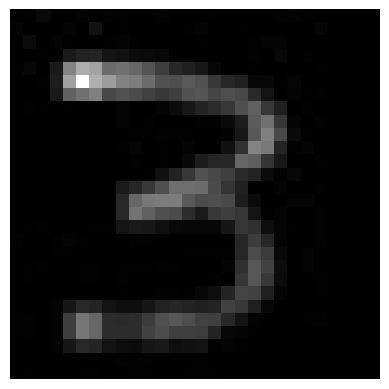

In [ ]:
# Mostrar la primera imagen
plt.imshow(img, cmap='gray')
plt.axis('off')
plt.show()

<p align="justify">
A continuación, se realiza el preprocesamiento de la imagen. Se aplana en un vector unidimensional y se escala. Es esencial que las nuevas imágenes sigan el mismo preprocesamiento que las imágenes de entrenamiento para asegurar que el modelo pueda interpretarlas correctamente.

In [ ]:
# Aplanar la imagen en un vector unidimensional
num_pixels = img.shape[0] * img.shape[1]                                        # Calcular la dimensión del vector unidimensional
img = img.flatten().astype('float32').reshape(1, num_pixels)                    # Aplanar la imagen y convertir a float32

# Escalar la imagen
img = img / 255

# Mostrar la forma del array para verificar
print(img.shape)

(1, 784)


Finalmente, se determina la clase que la red neuronal entrenada predice para la nueva imagen.

In [ ]:
np.argmax(model.predict(img))

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 27ms/step


3

La red neuronal ha realizado una predicción exitosa!!! identificando correctamente el número 3 en la imagen proporcionada.

<br>
<br>
<p align="center"><b>
💗
<font color="DeepPink">
Has llegado al final del cuaderno...
</font>
</p>
<br>



